In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch
import torchvision.transforms as transforms
from captum.attr import IntegratedGradients
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from model_finetuneado import AgeEstimationModel as AgeEstimationModelFinetuneado
from model_arista import AgeEstimationModel as AgeEstimationModelArista
from model_congelado import AgeEstimationModel as AgeEstimationModelCongelado
from config import config
import cv2

/Users/ninarigal/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/ninarigal/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [3]:
def overlay_heatmap(original_image, attr_map, alpha=0.6, cmap='jet'):
    """
    Superpone un mapa de calor sobre la imagen original usando OpenCV.
    """
    # Asegurarse de que attr_map esté en rango [0, 1]
    attr_map = np.maximum(attr_map, 0)  # Eliminar valores negativos
    attr_map = attr_map / attr_map.max()  # Escalar a [0, 1] si es necesario

    # Verificar que attr_map sea de tipo float32 o float64 y luego convertir a uint8
    attr_map = (attr_map * 255).astype(np.uint8)  # Escalar a [0, 255] y convertir a uint8

    # Verificar si es de una sola capa (escala de grises)
    if len(attr_map.shape) == 2:  # Si es un mapa de calor de un solo canal
        heatmap = cv2.applyColorMap(attr_map, cv2.COLORMAP_JET)
    elif len(attr_map.shape) == 3 and attr_map.shape[2] == 1:  # Si tiene una capa extra
        heatmap = cv2.applyColorMap(attr_map.squeeze(), cv2.COLORMAP_JET)
    else:
        raise ValueError("El mapa de atribución debe ser de una sola capa o tener un solo canal")

    # Asegurarse de que la imagen original esté en formato uint8
    if original_image.max() <= 1:
        original_image = (original_image * 255).astype(np.uint8)

    original_image_bgr = cv2.cvtColor(original_image, cv2.COLOR_RGB2BGR)

    # Redimensionar el mapa de calor al tamaño de la imagen original
    if original_image_bgr.shape[:2] != heatmap.shape[:2]:
        heatmap = cv2.resize(heatmap, (original_image_bgr.shape[1], original_image_bgr.shape[0]))

    # Superponer el mapa de calor sobre la imagen original
    overlay = cv2.addWeighted(original_image_bgr, 1 - alpha, heatmap, alpha, 0)

    # Convertir de BGR a RGB para mostrar correctamente en matplotlib
    overlay_rgb = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

    # Mostrar la imagen superpuesta
    plt.imshow(overlay_rgb)
    plt.axis('off')
    # Agregar el mapa de atribuciones como colorbar
    plt.colorbar()
    plt.show()

Forma de attr_upsampled: (3, 128, 128)
Nueva forma de attr_upsampled: (128, 128)


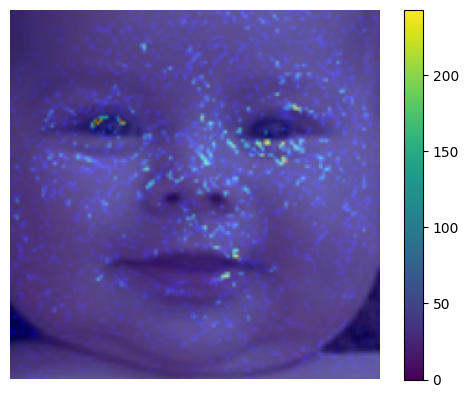

In [4]:
# Modelo Finetuneado
# Cargar el modelo y pesos
checkpoint_files = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/checkpoints/18EPOCHSALL_epoch-0-loss_valid-5.51.pt'
model = AgeEstimationModelFinetuneado(input_dim=3, output_nodes=1, model_name=config['model_name'], pretrain_weights='IMAGENET1K_V2').to(config['device'])
model.load_state_dict(torch.load(checkpoint_files, map_location=config['device']))
model.eval()

# Cargar la imagen
image_path = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/utkcropped/1_0_0_20161219204512212.jpg.chip.jpg'
image = Image.open(image_path).convert('RGB')

# Preprocesar la imagen
transform = transforms.Compose([
    transforms.Resize((config['img_width'], config['img_height'])),
    transforms.ToTensor(),
    transforms.Normalize(mean=config['mean'], std=config['std'])
])
input_data = transform(image).unsqueeze(0).to(config['device'])

# Convertir la imagen original a NumPy
original_image = np.array(image) / 255.0  # Normalizar a rango [0, 1]

# Crear objeto IntegratedGradients
ig = IntegratedGradients(model)

# Calcular las atribuciones con Integrated Gradients
attributions, delta = ig.attribute(input_data, target=0, return_convergence_delta=True)

# Interpolar el mapa de atribuciones al tamaño original
attr_upsampled = torch.nn.functional.interpolate(attributions, size=(config['img_height'], config['img_width']), mode='bilinear', align_corners=False)
attr_upsampled = attr_upsampled.squeeze(0).detach().cpu().numpy()

# Normalizar el mapa de atribuciones
attr_upsampled = np.maximum(attr_upsampled, 0)  # Eliminar valores negativos
attr_upsampled = attr_upsampled / attr_upsampled.max()  # Escalar a rango [0, 1]

# Verificar las dimensiones del mapa de atribuciones
print("Forma de attr_upsampled:", attr_upsampled.shape)

# Si el mapa tiene más de una capa (dimensión 3 o más), reducimos las dimensiones
if len(attr_upsampled.shape) > 2:
    # Reducir a 2D, obteniendo solo el primer canal si hay más de un canal
    attr_upsampled = attr_upsampled[0, :, :]  # O usa squeeze para eliminar dimensiones extra

# Asegurarnos de que ahora el mapa es 2D
print("Nueva forma de attr_upsampled:", attr_upsampled.shape)

# Ahora podemos llamar a overlay_heatmap
overlay_heatmap(original_image, attr_upsampled, alpha=0.6, cmap='jet')

Forma de attr_upsampled: (3, 128, 128)
Nueva forma de attr_upsampled: (128, 128)


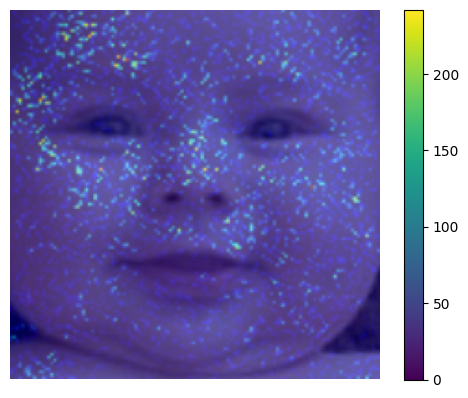

In [5]:
# Modelo Congelado
# Cargar el modelo y pesos
checkpoint_files = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/checkpoints/epoch-14-loss_valid-13.5.pt'

model = AgeEstimationModelCongelado(input_dim=3, output_nodes=1, model_name=config['model_name'], pretrain_weights='IMAGENET1K_V2').to(config['device'])
model.load_state_dict(torch.load(checkpoint_files, map_location=config['device']))
model.eval()

# Cargar la imagen
image_path = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/utkcropped/1_0_0_20161219204512212.jpg.chip.jpg'


image = Image.open(image_path).convert('RGB')

# Preprocesar la imagen
transform = transforms.Compose([
    transforms.Resize((config['img_width'], config['img_height'])),
    transforms.ToTensor(),
    transforms.Normalize(mean=config['mean'], std=config['std'])
])
input_data = transform(image).unsqueeze(0).to(config['device'])

# Convertir la imagen original a NumPy
original_image = np.array(image) / 255.0  # Normalizar a rango [0, 1]

# Crear objeto IntegratedGradients
ig = IntegratedGradients(model)

# Calcular las atribuciones con Integrated Gradients
attributions, delta = ig.attribute(input_data, target=0, return_convergence_delta=True)

# Interpolar el mapa de atribuciones al tamaño original
attr_upsampled = torch.nn.functional.interpolate(attributions, size=(config['img_height'], config['img_width']), mode='bilinear', align_corners=False)
attr_upsampled = attr_upsampled.squeeze(0).detach().cpu().numpy()

# Normalizar el mapa de atribuciones
attr_upsampled = np.maximum(attr_upsampled, 0)  # Eliminar valores negativos
attr_upsampled = attr_upsampled / attr_upsampled.max()  # Escalar a rango [0, 1]

# Verificar las dimensiones del mapa de atribuciones
print("Forma de attr_upsampled:", attr_upsampled.shape)

# Si el mapa tiene más de una capa (dimensión 3 o más), reducimos las dimensiones
if len(attr_upsampled.shape) > 2:
    # Reducir a 2D, obteniendo solo el primer canal si hay más de un canal
    attr_upsampled = attr_upsampled[0, :, :]  # O usa squeeze para eliminar dimensiones extra

# Asegurarnos de que ahora el mapa es 2D
print("Nueva forma de attr_upsampled:", attr_upsampled.shape)

# Ahora podemos llamar a overlay_heatmap
overlay_heatmap(original_image, attr_upsampled, alpha=0.6, cmap='jet')

Forma de attr_upsampled: (3, 128, 128)
Nueva forma de attr_upsampled: (128, 128)


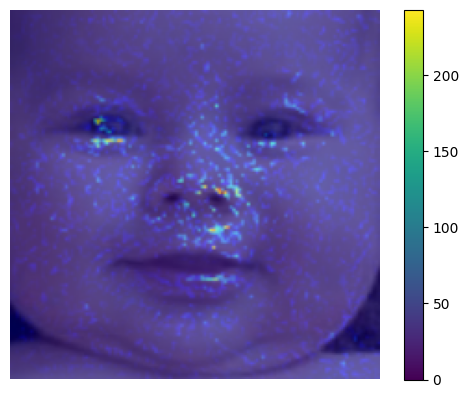

In [6]:
# Modelo Arista
# Cargar el modelo y pesos
checkpoint_files = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/checkpoints/capa_epoch-45-loss_valid-4.97.pt'
model = AgeEstimationModelArista(input_dim=3, output_nodes=1, model_name=config['model_name'], pretrain_weights='IMAGENET1K_V2').to(config['device'])
model.load_state_dict(torch.load(checkpoint_files, map_location=config['device']))
model.eval()

# Cargar la imagen
image_path = '/Users/ninarigal/UDESA/TERCER AÑO/VISIÓN ARTIFICIAL/tpf_vision-1/utkcropped/1_0_0_20161219204512212.jpg.chip.jpg'
image = Image.open(image_path).convert('RGB')

# Preprocesar la imagen
transform = transforms.Compose([
    transforms.Resize((config['img_width'], config['img_height'])),
    transforms.ToTensor(),
    transforms.Normalize(mean=config['mean'], std=config['std'])
])
input_data = transform(image).unsqueeze(0).to(config['device'])

# Convertir la imagen original a NumPy
original_image = np.array(image) / 255.0  # Normalizar a rango [0, 1]

# Crear objeto IntegratedGradients
ig = IntegratedGradients(model)

# Calcular las atribuciones con Integrated Gradients
attributions, delta = ig.attribute(input_data, target=0, return_convergence_delta=True)

# Interpolar el mapa de atribuciones al tamaño original
attr_upsampled = torch.nn.functional.interpolate(attributions, size=(config['img_height'], config['img_width']), mode='bilinear', align_corners=False)
attr_upsampled = attr_upsampled.squeeze(0).detach().cpu().numpy()

# Normalizar el mapa de atribuciones
attr_upsampled = np.maximum(attr_upsampled, 0)  # Eliminar valores negativos
attr_upsampled = attr_upsampled / attr_upsampled.max()  # Escalar a rango [0, 1]

# Verificar las dimensiones del mapa de atribuciones
print("Forma de attr_upsampled:", attr_upsampled.shape)

# Si el mapa tiene más de una capa (dimensión 3 o más), reducimos las dimensiones
if len(attr_upsampled.shape) > 2:
    # Reducir a 2D, obteniendo solo el primer canal si hay más de un canal
    attr_upsampled = attr_upsampled[0, :, :]  # O usa squeeze para eliminar dimensiones extra

# Asegurarnos de que ahora el mapa es 2D
print("Nueva forma de attr_upsampled:", attr_upsampled.shape)

# Ahora podemos llamar a overlay_heatmap
overlay_heatmap(original_image, attr_upsampled, alpha=0.6, cmap='jet')